# Phishing Website Detection — Machine Learning

**Goal:** train and evaluate supervised classifiers that decide whether a URL is **phishing** or **legitimate**, using classic ML (logistic regression, plus a model comparison) with standard metrics — accuracy, precision, recall, F1, ROC-AUC, and a confusion matrix.

**Dataset:** 10,000 URLs (5,000 phishing / 5,000 legitimate), 16 numeric URL/domain features derived from the UCI *Phishing Websites* work. Source: [shreyagopal/Phishing-Website-Detection-by-Machine-Learning-Techniques](https://github.com/shreyagopal/Phishing-Website-Detection-by-Machine-Learning-Techniques) (`DataFiles/5.urldata.csv`).

**How this fits the project:** this notebook is the *trained-model* core. The companion `phishprobe` package then **adversarially tests** a classifier's decision boundary — i.e. once you can build a detector, the next question is *how easily can it be evaded?*


## 1. Setup & imports

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve)

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
print('Libraries loaded. scikit-learn ready.')

Libraries loaded. scikit-learn ready.


## 2. Load the dataset

In [2]:
df = pd.read_csv('data/urldata.csv')
print('shape:', df.shape)
df.head()

shape: (10000, 18)


,Domain,Have_IP,Have_At,URL_Length,URL_Depth,Redirection,https_Domain,TinyURL,Prefix/Suffix,DNS_Record,Web_Traffic,Domain_Age,Domain_End,iFrame,Mouse_Over,Right_Click,Web_Forwards,Label
0,graphicriver.net,0,0,1,1,0,0,0,0,0,1,1,1,0,0,1,0,0
1,ecnavi.jp,0,0,1,1,1,0,0,0,0,1,1,1,0,0,1,0,0
2,hubpages.com,0,0,1,1,0,0,0,0,0,1,0,1,0,0,1,0,0
3,extratorrent.cc,0,0,1,3,0,0,0,0,0,1,0,1,0,0,1,0,0
4,icicibank.com,0,0,1,3,0,0,0,0,0,1,0,1,0,0,1,0,0


Each row is one URL. `Domain` is just an identifier (we drop it for modelling). `Label` is the target: **1 = phishing, 0 = legitimate**. The 16 features are binary/integer signals extracted from the URL and domain, e.g.:

| Feature | 1 means | Phishing intuition |
|---|---|---|
| `Have_IP` | URL uses a raw IP | real sites use domain names |
| `Have_At` | URL contains `@` | everything before `@` is ignored by browsers |
| `TinyURL` | a shortener (bit.ly, …) | hides the true destination |
| `Prefix/Suffix` | `-` in the domain | look-alike domains (`pay-pal.com`) |
| `https_Domain` | `https` inside the domain part | fakes the padlock in the text |
| `iFrame`, `Mouse_Over`, `Right_Click` | page uses these tricks | hide content / disable inspection |
| `Web_Traffic`, `Domain_Age` | low traffic / very new domain | phishing sites are short-lived |


## 3. Explore the data (EDA)

In [3]:
print('Missing values:', int(df.isnull().sum().sum()))
print('\nClass balance:')
print(df['Label'].value_counts().rename({0:'legit', 1:'phishing'}))
df.drop(columns=['Domain']).describe().T[['mean','min','max']]

Missing values: 0

Class balance:
Label
legit       5000
phishing    5000
Name: count, dtype: int64


,mean,min,max
Have_IP,0.0055,0.0,1.0
Have_At,0.0226,0.0,1.0
URL_Length,0.7734,0.0,1.0
URL_Depth,3.0720,0.0,20.0
Redirection,0.0135,0.0,1.0
https_Domain,0.0002,0.0,1.0
TinyURL,0.0903,0.0,1.0
Prefix/Suffix,0.0932,0.0,1.0
DNS_Record,0.1008,0.0,1.0
Web_Traffic,0.8457,0.0,1.0


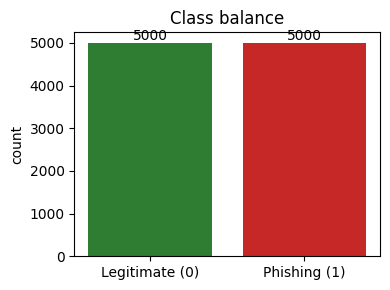

In [4]:
counts = df['Label'].value_counts().sort_index()
plt.figure(figsize=(4,3))
bars = plt.bar(['Legitimate (0)','Phishing (1)'], counts.values, color=['#2e7d32','#c62828'])
plt.title('Class balance'); plt.ylabel('count')
for i, v in enumerate(counts.values):
    plt.text(i, v + 60, str(v), ha='center')
plt.tight_layout(); plt.show()

**Which features lean phishing?** Pearson correlation of each feature with the label (positive = associated with phishing).

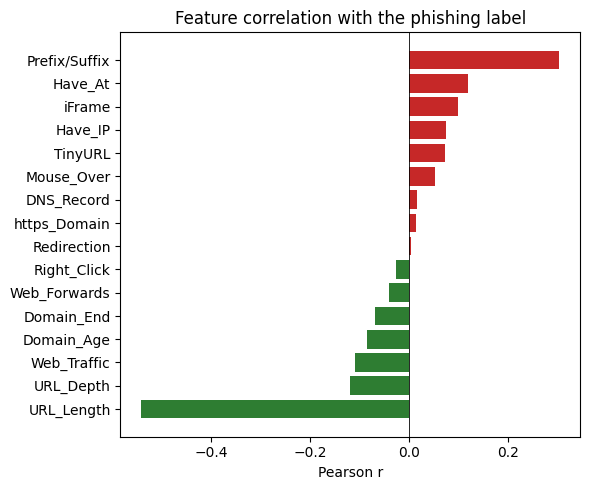

In [5]:
corr = df.drop(columns=['Domain']).corr()['Label'].drop('Label').sort_values()
plt.figure(figsize=(6,5))
colors = ['#2e7d32' if v < 0 else '#c62828' for v in corr.values]
plt.barh(corr.index, corr.values, color=colors)
plt.axvline(0, color='k', lw=0.6)
plt.title('Feature correlation with the phishing label'); plt.xlabel('Pearson r')
plt.tight_layout(); plt.show()

## 4. Features / label split & train-test split

In [6]:
X = df.drop(columns=['Domain', 'Label'])
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('train:', X_train.shape, '  test:', X_test.shape)
print('features:', list(X.columns))

train: (8000, 16)   test: (2000, 16)
features: ['Have_IP', 'Have_At', 'URL_Length', 'URL_Depth', 'Redirection', 'https_Domain', 'TinyURL', 'Prefix/Suffix', 'DNS_Record', 'Web_Traffic', 'Domain_Age', 'Domain_End', 'iFrame', 'Mouse_Over', 'Right_Click', 'Web_Forwards']


`stratify=y` keeps the 50/50 class ratio in both splits. `random_state=42` makes the split reproducible. We scale features (`StandardScaler`) inside a `Pipeline` for the distance/linear models so no single feature dominates just because of its range.

## 5. Model 1 — Logistic Regression (the interpretable linear model)

Logistic regression fits weights `w` and computes `p = sigmoid(w·x + b)` — a probability of *phishing*. It is the natural first model here: it's linear, fast, and its coefficients tell you **which features drive the decision**. (This is the same sigmoid idea used in the heuristic scorer in the `phishprobe` package — here the weights are *learned from data* instead of hand-set.)

In [7]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    # Fit, predict, and return a dict of standard classification metrics.
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    if hasattr(model, 'predict_proba'):
        score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        score = model.decision_function(X_te)
    else:
        score = pred
    return {
        'model': name,
        'accuracy': accuracy_score(y_te, pred),
        'precision': precision_score(y_te, pred),
        'recall': recall_score(y_te, pred),
        'f1': f1_score(y_te, pred),
        'roc_auc': roc_auc_score(y_te, score),
    }, pred

logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
metrics_lr, pred_lr = evaluate('Logistic Regression', logreg, X_train, y_train, X_test, y_test)

print('Logistic Regression — test-set metrics')
for k, v in metrics_lr.items():
    if k != 'model':
        print(f'  {k:10}: {v:.4f}')
print()
print(classification_report(y_test, pred_lr, target_names=['legit', 'phishing']))

Logistic Regression — test-set metrics
  accuracy  : 0.7965
  precision : 0.9230
  recall    : 0.6470
  f1        : 0.7607
  roc_auc   : 0.8744

              precision    recall  f1-score   support

       legit       0.73      0.95      0.82      1000
    phishing       0.92      0.65      0.76      1000

    accuracy                           0.80      2000
   macro avg       0.83      0.80      0.79      2000
weighted avg       0.83      0.80      0.79      2000



**Confusion matrix** — where the errors fall. Off-diagonal top-right = phishing missed (false negatives); bottom-left = legit flagged (false positives).

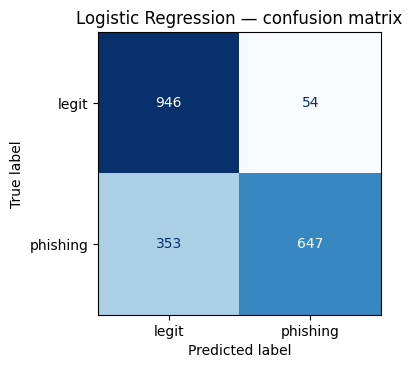

In [8]:
cm = confusion_matrix(y_test, pred_lr)
disp = ConfusionMatrixDisplay(cm, display_labels=['legit', 'phishing'])
fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title('Logistic Regression — confusion matrix'); plt.tight_layout(); plt.show()

### Interpreting the coefficients

Because logistic regression is linear, each feature has a single weight. Positive weight → pushes the prediction toward **phishing**; negative → toward **legitimate**. This is the interpretability an interviewer will ask about.

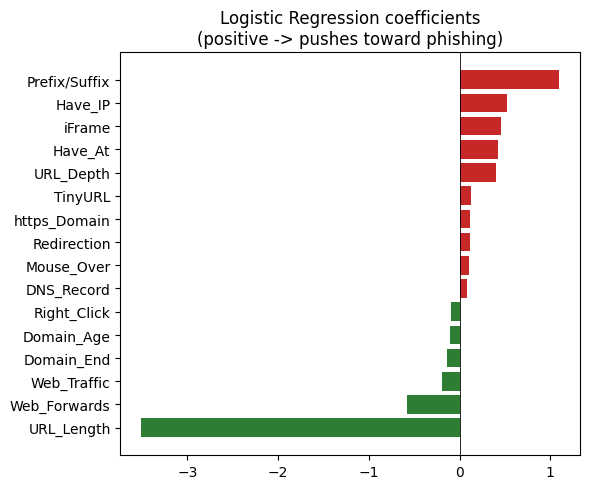

In [9]:
lr_est = logreg.named_steps['logisticregression']
coefs = pd.Series(lr_est.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(6, 5))
colors = ['#2e7d32' if v < 0 else '#c62828' for v in coefs.values]
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color='k', lw=0.6)
plt.title('Logistic Regression coefficients\n(positive -> pushes toward phishing)')
plt.tight_layout(); plt.show()

## 6. Linear Regression baseline — and why it's the wrong tool for classification

Ordinary **linear regression** predicts an unbounded continuous number, not a probability. You *can* threshold its output at 0.5 to force a class, but the raw predictions escape the `[0, 1]` range and it optimises the wrong loss. It's included here as an honest baseline (and because it's a common first instinct), to show *why* logistic regression is preferred for a yes/no problem.

In [10]:
linreg = make_pipeline(StandardScaler(), LinearRegression())
linreg.fit(X_train, y_train)
raw = linreg.predict(X_test)             # continuous output
pred_linr = (raw >= 0.5).astype(int)     # threshold into a class

print('Linear Regression (thresholded at 0.5)')
print(f'  raw output range : [{raw.min():.2f}, {raw.max():.2f}]   <-- not probabilities (escape 0..1)')
print(f'  accuracy         : {accuracy_score(y_test, pred_linr):.4f}')
print(f'  precision        : {precision_score(y_test, pred_linr):.4f}')
print(f'  recall           : {recall_score(y_test, pred_linr):.4f}')
print(f'  f1               : {f1_score(y_test, pred_linr):.4f}')

Linear Regression (thresholded at 0.5)
  raw output range : [-0.04, 1.67]   <-- not probabilities (escape 0..1)
  accuracy         : 0.7915
  precision        : 0.9280
  recall           : 0.6320
  f1               : 0.7519


## 7. Model comparison

In [11]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    'Decision Tree':       DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'SVM (RBF)':           make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
    'k-NN':                make_pipeline(StandardScaler(), KNeighborsClassifier()),
}

rows = []
for name, mdl in models.items():
    m, _ = evaluate(name, mdl, X_train, y_train, X_test, y_test)
    rows.append(m)

results = pd.DataFrame(rows).set_index('model').sort_values('f1', ascending=False)
results.round(4)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random Forest,0.8680,0.9259,0.800,0.8584,0.9257
k-NN,0.8475,0.8733,0.813,0.8421,0.8975
SVM (RBF),0.8330,0.9826,0.678,0.8024,0.8910
Decision Tree,0.8225,0.9924,0.650,0.7855,0.8760
Logistic Regression,0.7965,0.9230,0.647,0.7607,0.8744


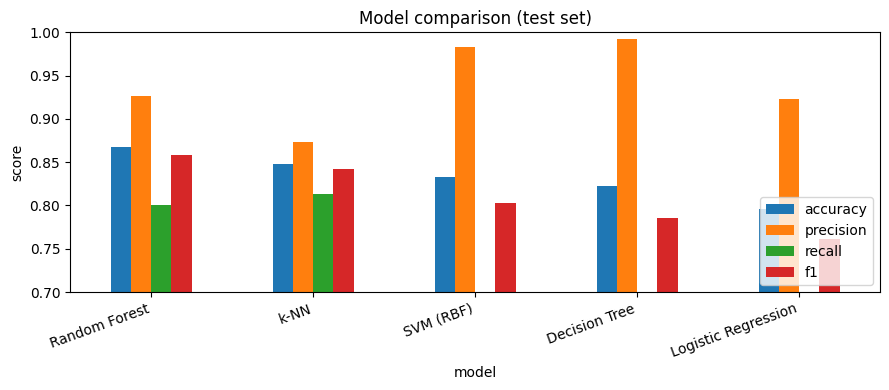

In [12]:
ax = results[['accuracy', 'precision', 'recall', 'f1']].plot(kind='bar', figsize=(9, 4))
plt.title('Model comparison (test set)'); plt.ylabel('score'); plt.ylim(0.7, 1.0)
plt.xticks(rotation=20, ha='right'); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 8. ROC curves

The ROC curve shows the trade-off between catching phishing (true-positive rate) and false alarms (false-positive rate) as the decision threshold moves. Area under the curve (AUC) closer to 1.0 is better. The models were already fitted in the comparison step above.

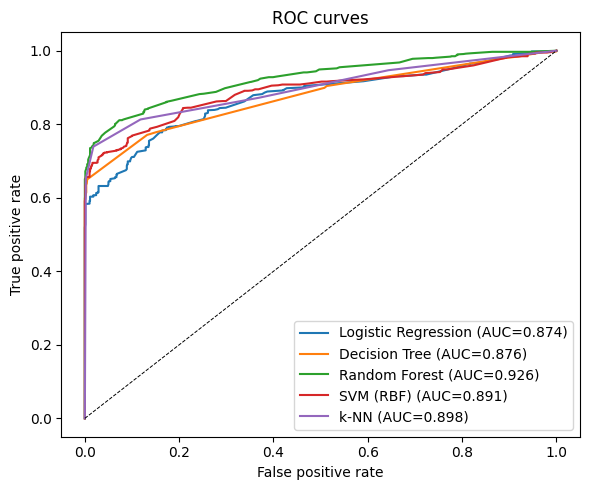

In [13]:
plt.figure(figsize=(6, 5))
for name, mdl in models.items():
    if hasattr(mdl, 'predict_proba'):
        s = mdl.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, s)
        plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, s):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.7)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves'); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 9. Cross-validation (is the headline number stable?)

A single train/test split can be lucky. 5-fold cross-validation refits on 5 different splits and reports the spread — a more honest estimate of generalisation.

In [14]:
cv = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    X, y, cv=5, scoring='f1')
print('Logistic Regression 5-fold F1 :', np.round(cv, 4))
print(f'mean = {cv.mean():.4f}   std = {cv.std():.4f}')

Logistic Regression 5-fold F1 : [0.7667 0.7734 0.7491 0.7794 0.7683]
mean = 0.7674   std = 0.0102


## 10. Results & conclusion

- **Random Forest leads** on this data (F1 ≈ 0.86, ROC-AUC ≈ 0.93) — a non-linear ensemble captures feature interactions the linear model can't.
- **Logistic Regression** trades some accuracy (F1 ≈ 0.76) for full **interpretability**: you can read its coefficients and explain *why* a URL was flagged. Note its **high precision (~0.92) but lower recall (~0.65)** — at the default 0.5 threshold it rarely false-alarms but misses phishing it's unsure about. Lowering the threshold trades precision for recall — that trade-off is exactly what the ROC curve traces.
- **Linear regression** underperforms and produces outputs that aren't probabilities — a concrete demonstration of why classification needs a classification model.
- Cross-validation confirms the logistic score is stable across folds (low std), so it isn't an artefact of one lucky split.

**Why the metrics beyond accuracy matter:** in email/URL filtering a **false positive** (blocking a legitimate site) is very costly, so precision and recall — not just accuracy — decide whether a model is deployable. On a balanced set like this, F1 (their harmonic mean) is the headline number.

### The bridge to adversarial testing

A strong test-set score answers *"is it accurate?"* — **not** *"is it robust?"* An attacker will actively modify a URL to slip past the model. That is exactly what the companion **`phishprobe`** package measures: it takes a classifier the model already flags and probes its **decision boundary** with meaning-preserving perturbations to find the smallest change that flips the verdict. Accuracy tells you how good the fence is; adversarial probing tells you where the hole is.
